# ML-02 — Research Question and Provisional Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/flyrank-bih/flyrank-ml-internship-starter/blob/main/work/notebooks/w01_research_question.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. My lane (or freestyle) and why

**Provisional lane: Lane 2 — Refresh / Content Opportunity Scoring.**

I picked this lane because it is the one where a ranked list directly matches how content teams work: they have limited review time and far more pages than they can look at. The starter data shows exactly that tension (see section 3): about 54% of pages carry a "declining" label, so "review everything" is not an option, and the pages that matter most hold a very large share of the exposure. The question is not "can I predict decline?" but **"which pages should a person look at first?"**

**One-paragraph frame.** For a content editor (or account manager) at a client site, deciding which pages to review first for refresh this month, I will build a *ranked review queue* (score, suggested action, reason codes, confidence label) from the anonymized starter dataset (later the warehouse release), scoring pages that are likely to be in real decline, measured by **Precision@K** (K = 20 and 50) against the base rate, validated with **client-holdout**. A wrong call costs editor time and a missed high-exposure page. A plain one-line rule is not enough on its own because the signal is spread across several columns and varies by segment — but it must be built first as the baseline to beat. I will claim only *observed / directional / decision-support* results.

**Fallback lane (if I change my mind by Week 4):** Lane 4 — CTR / Engagement Opportunity Scoring. In the starter data, thousands of visible pages sit on page one-to-two with very low CTR, so that lane has plenty of material too.

In [1]:
import os, sys, subprocess
import numpy as np
import pandas as pd

# Find the repo root (Colab: clone the public starter repo, which ships the same starter CSV).
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.isdir("data/raw"):
    if not os.path.isdir("flyrank-ml-internship-starter"):
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/flyrank-bih/flyrank-ml-internship-starter",
                        "flyrank-ml-internship-starter"], check=True)
    os.chdir("flyrank-ml-internship-starter")
else:
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
N_RAW_COLUMNS = df.shape[1]

# The starter label (a beginner PROXY, not a future outcome): trend_direction == "down"
df["is_declining"] = df["trend_direction"].eq("down")

print(f"Rows (one row = one pseudonymized page): {len(df):,}")
print(f"Clients (pseudonymized): {df['client_id'].nunique()}")
print(f"Columns in the CSV: {N_RAW_COLUMNS}")
print(f"Share of pages labeled declining: {df['is_declining'].mean():.1%}")

Rows (one row = one pseudonymized page): 30,000
Clients (pseudonymized): 32
Columns in the CSV: 44
Share of pages labeled declining: 54.2%


## 2. The question: decision, action, cost of a wrong call

**Search question.** Which pages on a client's site should be reviewed *first* for refresh, so that limited review time goes to pages that have real search exposure and show evidence of real decline?

**Unit of analysis.** One **page** (one pseudonymized content item) per row. Pages belong to a client, so I will always split train/test **by client**, never by page.

**Output.** A ranked review queue: a score per page, a suggested action (for example: refresh content, review title/meta because CTR is low for its position, or just monitor), short **reason codes** a reviewer can read, and a confidence label. It is a *list to review*, not a verdict.

**Who acts, and what they do.** A content editor (or an account manager preparing a refresh plan) opens the top K pages — say the top 50 — looks at each one, and decides: refresh it, rewrite its title/meta, or leave it alone.

**Cost of a wrong recommendation.**
- *False positive* (page is flagged but is not really declining, or a refresh would not help): wasted review time, and it displaces a better candidate from a short list. It can also lead to unnecessary edits on a page that was doing fine (a possible harm; this data cannot measure it).
- *False negative* (a high-exposure declining page is missed): it keeps losing impressions without anyone looking. This cost grows with exposure, and section 3 shows exposure is very concentrated in a small share of pages.
- Because the team can only review K pages, the everyday cost is false positives inside the top K — so **Precision@K** is my main metric, with a secondary check that weights pages by their impressions.

**Why data (and maybe ML) can help at all.** Nobody can eyeball tens of thousands of pages. A transparent rule can narrow the list, but section 3 shows the signal is uneven across position tiers and content types, and the simplest "stale and visible" rule only fires for a tiny number of pages. ML is worth trying **only if** it beats a well-built rule *and* the base rate under honest, client-holdout validation.

**Why this is not just "train a model".** I start from the decision (what gets reviewed first), the action (a human reviews and decides), and the cost (editor time vs. a missed page). I build the baseline rule first. I compare against the base rate, not just against a weak rule (section 3 shows why that matters). I validate by client, and I read my own top 20 by hand. If the model does not beat the rule, that is a result I will report.

**Provisional label and what I plan to improve.** For now the target is the starter proxy `trend_direction == "down"`. It is computed from the *current* window, so it is not a future outcome. My plan is to keep it for the starter work and then try a stronger label on the warehouse (features from a prior window, decline in a later window) before the end of Week 4 — and say so honestly if that does not work out.

In [2]:
# Capacity and cost framing. The two ASSUMPTIONS below are mine, not measured; edit them freely.
REVIEW_CAPACITY = 50          # ASSUMPTION: pages a team could realistically review per cycle
MINUTES_PER_REVIEW = 30       # ASSUMPTION: illustrative editor time per page review

visible = df[df["impressions_90d"] >= 500]                 # "enough exposure to matter" (a threshold I chose)
candidates = visible[visible["is_declining"]]               # visible AND labeled declining

print(f"Visible pages (>= 500 impressions in 90d): {len(visible):,}")
print(f"  ...of which labeled declining (candidates): {len(candidates):,}")
print(f"Review capacity K={REVIEW_CAPACITY} covers {REVIEW_CAPACITY/len(candidates):.1%} of those candidates")
print(f"Editor time for one cycle (assumption): about {REVIEW_CAPACITY*MINUTES_PER_REVIEW/60:.0f} hours")

# A random queue is NOT zero-accuracy: it already hits roughly the base rate.
base_visible = visible["is_declining"].mean()
print(f"\nBase rate of 'declining' among visible pages: {base_visible:.1%}")
print(f"A random top-{REVIEW_CAPACITY} from visible pages would contain about "
      f"{base_visible*REVIEW_CAPACITY:.0f} declining pages — so a useful queue has to beat THAT.")

Visible pages (>= 500 impressions in 90d): 16,726
  ...of which labeled declining (candidates): 9,961
Review capacity K=50 covers 0.5% of those candidates
Editor time for one cycle (assumption): about 25 hours

Base rate of 'declining' among visible pages: 59.6%
A random top-50 from visible pages would contain about 30 declining pages — so a useful queue has to beat THAT.


## 3. Quick look at the data (2-3 real numbers)

The code cell below computes four numbers from the starter CSV (all computed live, nothing typed in by hand except one clearly labeled source line). What they say, in plain words:

1. **Many pages carry the label, so there is no way to "review them all".** About **54%** of the 30,000 pages are labeled declining (about 59% if the "new" pages, which have no real trend yet, are left out). There is plenty to do and not enough time to do it.
2. **Exposure is very concentrated.** The top 10% of pages hold about **70%** of all impressions, and the top 1% hold about **25%**. Getting the *order* of review right matters more than reviewing more pages.
3. **The signal is uneven, so a one-line rule is too blunt.** The share labeled declining is about **24%** for `top_3` pages but about **61%** for `striking` pages, and about **29%** for `feedly article` content versus about **56%** for `keyword article`. Also, the simple "stale (180+ days) and visible (500+ impressions)" rule from the starter fires for only **17** of 30,000 pages.
4. **The bar is the base rate, not the weak baseline.** In the starter pipeline, the baseline rule's top 50 were only **24%** declining, while about **54%** of all pages carry the label — so that baseline did *worse* than a random pick would. The random forest's **74%** is a lift of about **1.4x over the base rate**, not the "3x" you get when you compare only against the baseline. This is why I will compare against both the base rate and a *good* rule.

*All numbers are observed on a 30,000-row anonymized starter slice (32 pseudonymized clients). They are directional and do not describe the full warehouse.*

1) Declining label rate: all pages 54.2% | excluding 'new' pages 58.6%
2) Top 1% of pages hold 24.9% of all 90-day impressions
2) Top 10% of pages hold 70.2% of all 90-day impressions

3) Share labeled declining, by position_tier:
position_tier
top_3       24.1
deep        34.4
page_3_5    56.2
page_1      57.0
striking    61.0

   Share labeled declining, by content_type:
content_type
feedly article        28.7
keyword article       56.1
comparison article    57.2

   Pages firing the 'stale >=180d AND visible >=500 impressions' rule: 17 of 30,000

4) Base rate (all pages): 0.542
   starter baseline rule  Precision@50 = 0.24  ->  0.44x the base rate
   random forest          Precision@50 = 0.74  ->  1.37x the base rate


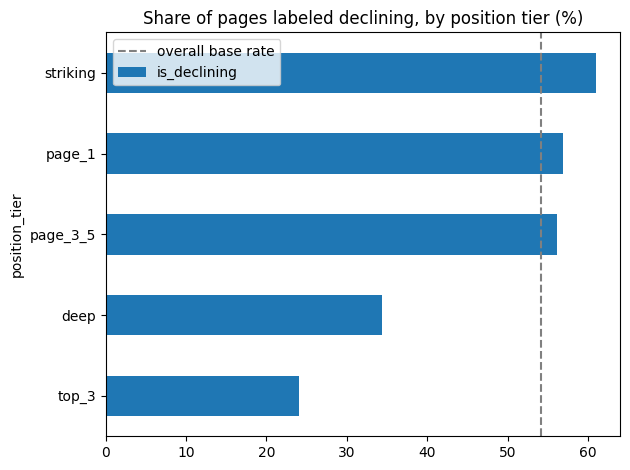

In [3]:
import matplotlib.pyplot as plt

# 1) Base rate of the label
print(f"1) Declining label rate: all pages {df['is_declining'].mean():.1%} | "
      f"excluding 'new' pages {df.loc[df['trend_direction']!='new','is_declining'].mean():.1%}")

# 2) Exposure concentration
s = df["impressions_90d"].sort_values(ascending=False)
total = s.sum()
for q in (0.01, 0.10):
    share = s.head(int(len(s) * q)).sum() / total
    print(f"2) Top {q:.0%} of pages hold {share:.1%} of all 90-day impressions")

# 3) Signal varies by segment, and the plain 'stale x visible' rule is narrow
by_tier = df.groupby("position_tier")["is_declining"].mean().sort_values()
by_type = df.groupby("content_type")["is_declining"].mean().sort_values()
print("\n3) Share labeled declining, by position_tier:")
print((by_tier * 100).round(1).to_string())
print("\n   Share labeled declining, by content_type:")
print((by_type * 100).round(1).to_string())
stale_visible = (df["days_since_last_update"] >= 180) & (df["impressions_90d"] >= 500)
print(f"\n   Pages firing the 'stale >=180d AND visible >=500 impressions' rule: {stale_visible.sum()} of {len(df):,}")

# 4) The bar to beat: base rate vs the starter pipeline's top-50 precision.
# SOURCE (typed in, not computed here): notebook 01 run of scripts/run_all.py and docs lane guide section 5.
STARTER_P50 = {"starter baseline rule": 0.24, "random forest": 0.74}
base = df["is_declining"].mean()
print(f"\n4) Base rate (all pages): {base:.3f}")
for name, p50 in STARTER_P50.items():
    print(f"   {name:<22} Precision@50 = {p50:.2f}  ->  {p50/base:.2f}x the base rate")

ax = (by_tier * 100).plot(kind="barh", title="Share of pages labeled declining, by position tier (%)")
ax.axvline(base * 100, color="gray", linestyle="--", label="overall base rate")
ax.legend(); plt.tight_layout(); plt.show()

## 4. Careful words: what I can and can't claim

**What my work will be able to say**
- *Observed:* in this anonymized starter sample, pages with certain signals (position tier, content type, exposure, age) are labeled declining more or less often than others.
- *Directional:* a ranking built from these signals puts more declining-labeled pages in its top K than a random pick or a simple rule does — if and only if the validation (by client) shows that.
- *Decision-support:* the output is a prioritized list for a human to review. A person still decides what to do with each page.

**What my work will never say**
- That refreshing a page **causes** it to recover. This data is observational; proving cause would need an experiment or another causal design.
- Anything about **how Google's algorithm works**, or that a signal is a "ranking factor".
- That results from this 30,000-row sample hold for the full warehouse or for any single client. They have to be earned again with proper validation.
- That "declining" here means a true long-run decline: the current label is a **proxy** computed from the current window, and it can also reflect seasonality, consolidation with a sibling page, or noise.

**Choices that are policy, not truth.** "Visible" (500+ impressions), the review capacity (K = 50) and the editor-time estimate (30 minutes) are my own assumptions, and I will show how results change when they change.

**Guardrails I will follow.** `trend_direction` and `trend_pct` are never features (the label comes from them, which would be leakage). IDs are used only for grouping and splitting. No client names, URLs, raw queries or titles appear anywhere; the data does not contain them, and the check below confirms it.

In [4]:
# (a) The label is derived from trend_pct -> these two columns must never be model features.
print("trend_pct (%) range per trend_direction — shows the label is built from trend_pct:")
print(df.groupby("trend_direction")["trend_pct"].agg(["min", "max"]).round(1).to_string())

# (b) Columns I will keep OUT of features (decided now, written down early)
EXCLUDED_FROM_FEATURES = ["trend_direction", "trend_pct", "is_declining", "content_id", "client_id"]
print("\nExcluded from features:", EXCLUDED_FROM_FEATURES)

# (c) Public-safety check: no raw URL / domain / query / title style columns in the starter data
risky = [c for c in df.columns if any(k in c.lower() for k in ("url", "domain", "query", "title", "keyword_text", "name"))]
print("Columns that look like raw URL/domain/query/title/name fields:", risky if risky else "none")

trend_pct (%) range per trend_direction — shows the label is built from trend_pct:
                   min      max
trend_direction                
down            -100.0    -20.0
flat               NaN      NaN
new                NaN      NaN
stable           -20.0     20.0
up                20.0  44900.0

Excluded from features: ['trend_direction', 'trend_pct', 'is_declining', 'content_id', 'client_id']
Columns that look like raw URL/domain/query/title/name fields: none


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.